# 02 — Model and Diffusion

## Scientific question

**How can a very small from-scratch conditional DDPM represent image and text information?**

The executable checks instantiate production classes on CPU. They do not load checkpoints or run a reverse sampling trajectory.

## Environment & reproducibility setup

In [1]:
from __future__ import annotations

import json
import platform
from importlib.metadata import version
from pathlib import Path

import matplotlib.pyplot as plt
import torch


def find_project_root(start: Path | None = None) -> Path:
    current = (start or Path.cwd()).resolve()
    for candidate in (current, *current.parents):
        if (candidate / "pyproject.toml").is_file() and (candidate / "src" / "tiny_avatar_diffusion").is_dir():
            return candidate
    raise RuntimeError(
        "Repository root not found. Run this notebook from inside the Tiny Avatar Diffusion repository."
    )


PROJECT_ROOT = find_project_root()
environment = {
    "python": platform.python_version(),
    "package": version("tiny-avatar-diffusion"),
    "project_root": PROJECT_ROOT.name,
    "project_markers_verified": True,
    "torch": torch.__version__,
    "cuda_available": torch.cuda.is_available(),
    "selected_device": "cpu",
}
environment

{'python': '3.12.4',
 'package': '0.0.0',
 'project_root': 'DL_Project',
 'project_markers_verified': True,
 'torch': '2.5.1+cu121',
 'cuda_available': True,
 'selected_device': 'cpu'}

## Design constraints and Tiny U-Net

The frozen model operates in 32×32 pixel space. Its U-Net uses 64 → 128 → 128 encoder channels at 32×32, 16×16, and 8×8. Each encoder and decoder stage has two residual blocks. Residual blocks use GroupNorm and SiLU; skip connections reconnect matching spatial scales. There is no visual self-attention.

In [2]:
from tiny_avatar_diffusion.frozen_results import load_frozen_results
from tiny_avatar_diffusion.text_conditioning import TextConditioningConfig, TextConditioningEncoder
from tiny_avatar_diffusion.unet import ConditionalTinyUNet, TinyUNet

text_config = TextConditioningConfig()
text_encoder = TextConditioningEncoder(text_config).eval()
conditional_unet = ConditionalTinyUNet().eval()
unconditional_unet = TinyUNet().eval()
frozen = load_frozen_results()

measured_counts = {
    "conditional": sum(p.numel() for p in text_encoder.parameters())
    + sum(p.numel() for p in conditional_unet.parameters()),
    "unconditional": sum(p.numel() for p in unconditional_unet.parameters()),
}
assert measured_counts == frozen["parameter_counts"]
{
    "encoder_channels": [64, 128, 128],
    "residual_blocks_per_stage": 2,
    "normalization": "GroupNorm",
    "activation": "SiLU",
    "visual_self_attention": False,
    "parameter_counts": measured_counts,
}

{'encoder_channels': [64, 128, 128],
 'residual_blocks_per_stage': 2,
 'normalization': 'GroupNorm',
 'activation': 'SiLU',
 'visual_self_attention': False,
 'parameter_counts': {'conditional': 4723907, 'unconditional': 4595779}}

## Scratch text encoder and cross-attention conditioning

The text encoder is trained from scratch: width 64, two pre-LayerNorm Transformer blocks, four self-attention heads, a 256-wide GELU feed-forward network, sinusoidal positions, and training dropout 0.1. Its token representations condition the image branch through image-query/text-key-value cross-attention at the 8×8 bottleneck. The attention width is 64 with four heads.

In [3]:
batch_size = 1
input_ids = torch.tensor([[1, 4, 18, 23, 42, 15, 2]], dtype=torch.long)
attention_mask = torch.ones_like(input_ids)
x_t = torch.zeros(batch_size, 3, 32, 32)
timesteps = torch.tensor([500], dtype=torch.long)

with torch.inference_mode():
    context = text_encoder(input_ids, attention_mask)
    epsilon_prediction = conditional_unet(x_t, timesteps, context, attention_mask)

shape_checks = {
    "input_image": tuple(x_t.shape),
    "context_tokens": tuple(context.shape),
    "epsilon_prediction": tuple(epsilon_prediction.shape),
}
assert shape_checks == {
    "input_image": (1, 3, 32, 32),
    "context_tokens": (1, 7, 64),
    "epsilon_prediction": (1, 3, 32, 32),
}
shape_checks

{'input_image': (1, 3, 32, 32),
 'context_tokens': (1, 7, 64),
 'epsilon_prediction': (1, 3, 32, 32)}

## Architecture diagram

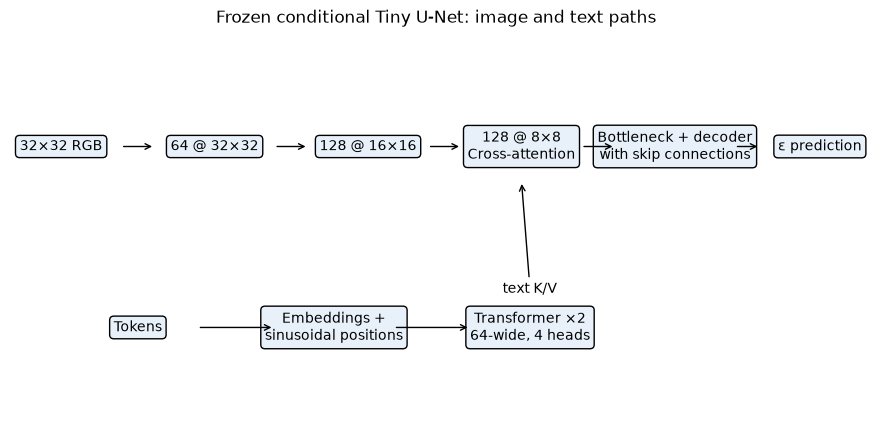

In [4]:
fig, ax = plt.subplots(figsize=(11, 5))
ax.axis("off")
image_path = [
    (0.06, 0.70, "32×32 RGB"),
    (0.24, 0.70, "64 @ 32×32"),
    (0.42, 0.70, "128 @ 16×16"),
    (0.60, 0.70, "128 @ 8×8\nCross-attention"),
    (0.78, 0.70, "Bottleneck + decoder\nwith skip connections"),
    (0.95, 0.70, "ε prediction"),
]
text_path = [
    (0.15, 0.23, "Tokens"),
    (0.38, 0.23, "Embeddings +\nsinusoidal positions"),
    (0.61, 0.23, "Transformer ×2\n64-wide, 4 heads"),
]
for x, y, label in image_path + text_path:
    ax.text(x, y, label, ha="center", va="center", bbox={"boxstyle": "round", "facecolor": "#e8f1fa"})
for path in (image_path, text_path):
    for left, right in zip(path[:-1], path[1:], strict=True):
        ax.annotate("", xy=(right[0] - 0.07, right[1]), xytext=(left[0] + 0.07, left[1]), arrowprops={"arrowstyle": "->"})
ax.annotate("text K/V", xy=(0.60, 0.61), xytext=(0.61, 0.32), ha="center", arrowprops={"arrowstyle": "->"})
ax.set_title("Frozen conditional Tiny U-Net: image and text paths")
plt.show()

## DDPM forward process, objective, and reverse step

The implemented forward marginal is

$$q(x_t\mid x_0)=\mathcal{N}\!\left(\sqrt{\bar\alpha_t}x_0,(1-\bar\alpha_t)I\right),$$

with reparameterized noising

$$x_t=\sqrt{\bar\alpha_t}x_0+\sqrt{1-\bar\alpha_t}\,\epsilon.$$

Training minimizes

$$\mathbb{E}\left[\lVert\epsilon-\epsilon_\theta(x_t,t,c)\rVert_2^2\right].$$

At sampling time, the network predicts epsilon. The schedule reconstructs predicted $x_0$, clips that reconstruction to the image domain, forms the fixed-small posterior mean, and adds posterior noise for ancestral DDPM sampling (except at the terminal step).

## Frozen schedule inspection

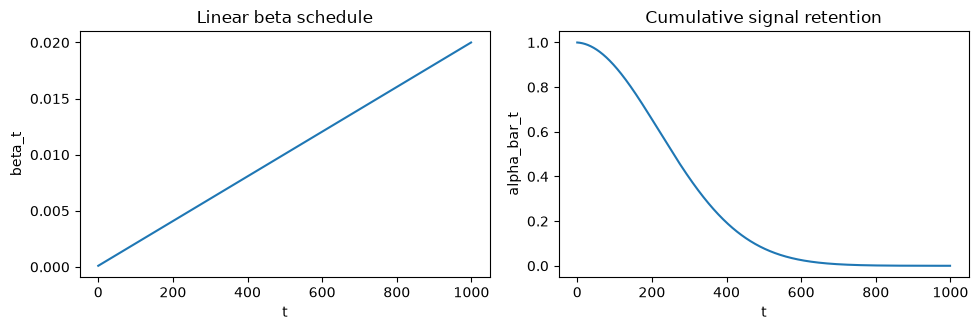

{'T': 1000,
 'beta_start': 9.999999747378752e-05,
 'beta_end': 0.019999999552965164}

In [5]:
from tiny_avatar_diffusion.diffusion import LinearDDPMSchedule

schedule = LinearDDPMSchedule()
assert schedule.betas.shape == (1000,)
assert torch.isclose(schedule.betas[0], torch.tensor(1e-4))
assert torch.isclose(schedule.betas[-1], torch.tensor(0.02))

fig, axes = plt.subplots(1, 2, figsize=(10, 3.4))
axes[0].plot(schedule.betas.numpy())
axes[0].set(title="Linear beta schedule", xlabel="t", ylabel="beta_t")
axes[1].plot(schedule.alphas_cumprod.numpy())
axes[1].set(title="Cumulative signal retention", xlabel="t", ylabel="alpha_bar_t")
plt.tight_layout()
plt.show()
{"T": len(schedule.betas), "beta_start": float(schedule.betas[0]), "beta_end": float(schedule.betas[-1])}

## Design rationale

- **32×32 pixel-space diffusion:** matches the canonical avatar resolution and keeps training/sampling tractable.
- **Compact U-Net:** preserves multi-scale spatial structure within the V1 parameter budget.
- **Scratch Transformer:** avoids pretrained-language dependencies for a fixed five-token grammar.
- **Cross-attention only at 8×8:** injects token context where receptive fields are broad while avoiding visual self-attention cost.
- **Epsilon prediction, linear beta, fixed-small variance:** form one conventional, fully frozen DDPM contract.
- **No CFG in MAIN:** V1 evaluates direct learned conditioning without a separate guidance mechanism or guidance-scale tuning.

These are frozen design constraints, not controls exposed by the release interfaces.